<a href="https://colab.research.google.com/github/Kalpaniii01/FindJob/blob/main/BigData_CA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1) INSTALL & START SPARK
!pip -q install pyspark==3.5.1 pyarrow fastparquet kaggle

import os, shutil, math, json, gc, datetime as dt
from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = (SparkSession.builder
         .appName("AppStore-BigData")
         .config("spark.sql.shuffle.partitions", "200")   # tune when scaling
         .config("spark.driver.memory", "6g")
         .getOrCreate())

spark


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 15.6 MB/s eta 0:00:00


In [2]:
# 2A) KAGGLE DOWNLOAD (use this for 100MB+ datasets)
# Kaggle: Account → Create New API Token → downloads kaggle.json

from google.colab import files
print("Upload kaggle.json (from Kaggle > Account)")
files.upload()

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

DATA_DIR = "/content/data"; os.makedirs(DATA_DIR, exist_ok=True)
KAGGLE_DATASET = "gauthamp10/apple-appstore-apps"

!kaggle datasets download -d $KAGGLE_DATASET -p $DATA_DIR
!unzip -o $DATA_DIR/*.zip -d $DATA_DIR
!ls -lh $DATA_DIR


Upload kaggle.json (from Kaggle > Account)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/gauthamp10/apple-appstore-apps
License(s): Attribution 4.0 International (CC BY 4.0)
 66% 77.0M/117M [00:00<00:00, 806MB/s]
100% 117M/117M [00:00<00:00, 781MB/s] 
Archive:  /content/data/apple-appstore-apps.zip
  inflating: /content/data/appleAppData.csv  
total 505M
-rw-r--r-- 1 root root 388M Oct 14  2021 appleAppData.csv
-rw-r--r-- 1 root root 117M Oct 14  2021 apple-appstore-apps.zip


In [3]:
# 3) LOAD CSV INTO SPARK
csv_files = [f for f in os.listdir(DATA_DIR) if f.lower().endswith(".csv")]
assert csv_files, "No CSV found in /content/data"
INPUT_PATH = f"{DATA_DIR}/{csv_files[0]}"
print("Reading:", INPUT_PATH)

df = (spark.read
      .option("header", True)
      .option("inferSchema", True)       # schema-on-read
      .csv(INPUT_PATH))

print("Rows:", df.count(), "Cols:", len(df.columns))
print("Columns (first 25):", df.columns[:25])
df.printSchema()


Reading: /content/data/appleAppData.csv
Rows: 1230376 Cols: 21
Columns (first 25): ['App_Id', 'App_Name', 'AppStore_Url', 'Primary_Genre', 'Content_Rating', 'Size_Bytes', 'Required_IOS_Version', 'Released', 'Updated', 'Version', 'Price', 'Currency', 'Free', 'DeveloperId', 'Developer', 'Developer_Url', 'Developer_Website', 'Average_User_Rating', 'Reviews', 'Current_Version_Score', 'Current_Version_Reviews']
root
 |-- App_Id: string (nullable = true)
 |-- App_Name: string (nullable = true)
 |-- AppStore_Url: string (nullable = true)
 |-- Primary_Genre: string (nullable = true)
 |-- Content_Rating: string (nullable = true)
 |-- Size_Bytes: string (nullable = true)
 |-- Required_IOS_Version: string (nullable = true)
 |-- Released: string (nullable = true)
 |-- Updated: string (nullable = true)
 |-- Version: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Currency: string (nullable = true)
 |-- Free: string (nullable = true)
 |-- DeveloperId: string (nullable = true)
 |--

In [4]:
# 4) CLEAN HEADERS & TYPES
for c in df.columns:
    df = df.withColumnRenamed(c, c.strip().replace(" ", "_"))

num_candidates  = ["Size_Bytes","Price","Average_User_Rating","Reviews",
                   "Current_Version_Score","Current_Version_Reviews"]
date_candidates = ["Released","Updated","Released_Date","Updated_Date"]

for c in num_candidates:
    if c in df.columns:
        df = df.withColumn(c, F.col(c).cast("double"))

for c in date_candidates:
    if c in df.columns:
        df = df.withColumn(c, F.to_timestamp(F.col(c)))

# Feature engineering
if "Size_Bytes" in df.columns:
    df = df.withColumn("Size_MB", F.col("Size_Bytes")/F.lit(1024**2))\
           .withColumn("Size_GB", F.col("Size_Bytes")/F.lit(1024**3))

if "Price" in df.columns:
    df = df.withColumn("Is_Free", F.when((F.col("Price").isNull()) | (F.col("Price")==0), 1).otherwise(0))\
           .withColumn("Log1p_Price", F.log1p(F.greatest(F.col("Price"), F.lit(0.0))))

if "Reviews" in df.columns:
    df = df.withColumn("Log1p_Reviews", F.log1p(F.greatest(F.col("Reviews"), F.lit(0.0))))

today = F.current_timestamp()
if "Released" in df.columns:
    df = df.withColumn("App_Age_days", F.datediff(today, F.col("Released")))
if "Updated" in df.columns:
    df = df.withColumn("Days_Since_Update", F.datediff(today, F.col("Updated")))

df.cache()
print("Cached rows:", df.count())


Cached rows: 1230376


In [5]:
# 5) DEDUPE & QUALITY CHECKS
id_cols = [c for c in ["App_Id","AppID","id"] if c in df.columns]
if id_cols:
    before = df.count()
    df = df.dropDuplicates(id_cols)
    after = df.count()
    print(f"Deduped by {id_cols}: {before} -> {after}")

# Missingness summary (big-data friendly)
na_counts = (df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])
               .toPandas().T.sort_values(0, ascending=False))
na_counts.head(20)

# Approximate 99th percentile caps (scalable quantiles)
for c in ["Price","Size_MB"]:
    if c in df.columns:
        q99 = df.approxQuantile(c, [0.99], 0.01)[0]
        df = df.withColumn(f"{c}_Capped", F.when(F.col(c) > F.lit(q99), F.lit(q99)).otherwise(F.col(c)))


Deduped by ['App_Id']: 1230376 -> 1230376


In [6]:
na_counts.head(20)

,0
Developer_Website,643972
Developer_Url,1109
Price,493
Size_Bytes,229
Size_MB,229
Size_GB,229
Average_User_Rating,20
App_Age_days,8
Released,8
Days_Since_Update,3


In [7]:
# Drop highly missing columns
drop_cols = ["Developer_Website"]  # not relevant for modeling
df = df.drop(*drop_cols)

In [8]:
#Filling Minor Missing Values
from pyspark.sql.functions import lit

# Fill Price with 0 where null
if "Price" in df.columns:
    df = df.fillna({"Price": 0.0})

# Fill Size_Bytes with median (approxQuantile)
if "Size_Bytes" in df.columns:
    median_size = df.approxQuantile("Size_Bytes", [0.5], 0.01)[0]
    df = df.fillna({"Size_Bytes": median_size,
                    "Size_MB": median_size/(1024**2),
                    "Size_GB": median_size/(1024**3)})


In [9]:
# Drop small-missing rows
small_missing_cols = ["Average_User_Rating","Released","Updated","Reviews","App_Age_days","Days_Since_Update"]
for col in small_missing_cols:
    if col in df.columns:
        df = df.filter(F.col(col).isNotNull())

In [10]:
# === AFTER MISSING VALUE HANDLING ===

# Show new row & column counts
print(f"New dataset shape: {df.count()} rows × {len(df.columns)} columns")

# Print schema (types)
df.printSchema()

# Show first 5 rows to verify transformations
df.show(5, truncate=False)

# Describe numeric columns
numeric_cols = [field.name for field in df.schema.fields if isinstance(field.dataType, T.NumericType)]
df.select(numeric_cols).describe().show()

# Re-check missingness
na_counts_new = (df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])
                   .toPandas().T.sort_values(0, ascending=False))
print("\nMissing values after cleaning:")
display(na_counts_new.head(20))


New dataset shape: 1230353 rows × 29 columns
root
 |-- App_Id: string (nullable = true)
 |-- App_Name: string (nullable = true)
 |-- AppStore_Url: string (nullable = true)
 |-- Primary_Genre: string (nullable = true)
 |-- Content_Rating: string (nullable = true)
 |-- Size_Bytes: double (nullable = false)
 |-- Required_IOS_Version: string (nullable = true)
 |-- Released: timestamp (nullable = true)
 |-- Updated: timestamp (nullable = true)
 |-- Version: string (nullable = true)
 |-- Price: double (nullable = false)
 |-- Currency: string (nullable = true)
 |-- Free: string (nullable = true)
 |-- DeveloperId: string (nullable = true)
 |-- Developer: string (nullable = true)
 |-- Developer_Url: string (nullable = true)
 |-- Average_User_Rating: double (nullable = true)
 |-- Reviews: double (nullable = true)
 |-- Current_Version_Score: double (nullable = true)
 |-- Current_Version_Reviews: double (nullable = true)
 |-- Size_MB: double (nullable = false)
 |-- Size_GB: double (nullable = fals

,0
Developer_Url,1109
Price_Capped,487
Size_MB_Capped,221
App_Name,0
App_Id,0
Size_Bytes,0
Required_IOS_Version,0
Released,0
Updated,0
Version,0


In [11]:
# 6) EDA — SCALABLE QUERIES
df.createOrReplaceTempView("apps")

# Top categories
if "Primary_Genre" in df.columns:
    spark.sql("""
        SELECT Primary_Genre, COUNT(*) AS apps
        FROM apps
        GROUP BY Primary_Genre
        ORDER BY apps DESC
        LIMIT 15
    """).show(15, truncate=False)

# Free vs Paid — rating stats
if set(["Is_Free","Average_User_Rating"]).issubset(df.columns):
    spark.sql("""
        SELECT Is_Free,
               COUNT(*) AS n,
               AVG(Average_User_Rating) AS avg_rating,
               percentile_approx(Average_User_Rating, 0.5) AS median_rating
        FROM apps
        WHERE Average_User_Rating IS NOT NULL
        GROUP BY Is_Free
    """).show()

# Pairwise correlations (selected numerics)
num_cols = [c for c in ["Average_User_Rating","Price","Reviews","Size_MB","App_Age_days","Days_Since_Update"] if c in df.columns]
from itertools import combinations
for a,b in combinations(num_cols, 2):
    try:
        print(f"corr({a},{b}) = {df.stat.corr(a,b)}")
    except Exception as e:
        pass

# Approx distinct developers (HyperLogLog)
if "Developer" in df.columns:
    approx_devs = df.agg(F.approx_count_distinct("Developer").alias("approx_distinct_devs")).first()[0]
    print("Approx distinct developers:", approx_devs)


+----------------+------+
|Primary_Genre   |apps  |
+----------------+------+
|Games           |193743|
|Business        |128295|
|Education       |119171|
|Utilities       |94007 |
|Lifestyle       |84564 |
|Food & Drink    |73157 |
|Health & Fitness|60724 |
|Productivity    |59430 |
|Entertainment   |53140 |
|Shopping        |49537 |
|Finance         |44983 |
|Travel          |43726 |
|Sports          |31455 |
|Music           |29898 |
|Medical         |27995 |
+----------------+------+

+-------+-------+------------------+-------------+
|Is_Free|      n|        avg_rating|median_rating|
+-------+-------+------------------+-------------+
|      1|1127851|1.7882984449718866|          0.0|
|      0| 102502|1.7895467139177794|          0.0|
+-------+-------+------------------+-------------+

corr(Average_User_Rating,Price) = -0.010434297899662123
corr(Average_User_Rating,Reviews) = 0.02216664118503371
corr(Average_User_Rating,Size_MB) = 0.048465057981947904
corr(Average_User_Rating,App_

/tmp/ipython-input-3710430890.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="Primary_Genre", data=top_cats_pdf, palette="viridis")


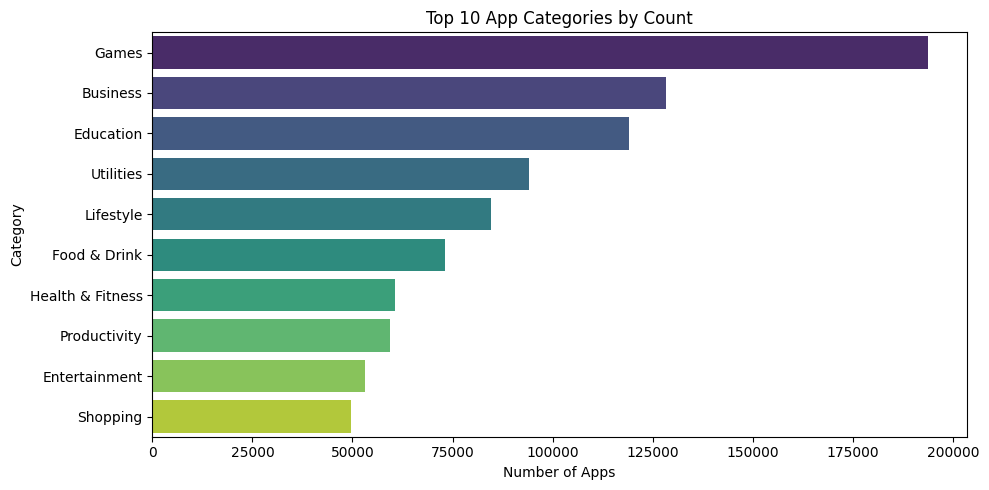

In [12]:
#Top 10 Categories by Number of Apps
# Sample top categories from Spark
top_cats_pdf = (df.groupBy("Primary_Genre")
                  .count()
                  .orderBy(F.desc("count"))
                  .limit(10)
                  .toPandas())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.barplot(x="count", y="Primary_Genre", data=top_cats_pdf, palette="viridis")
plt.title("Top 10 App Categories by Count")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


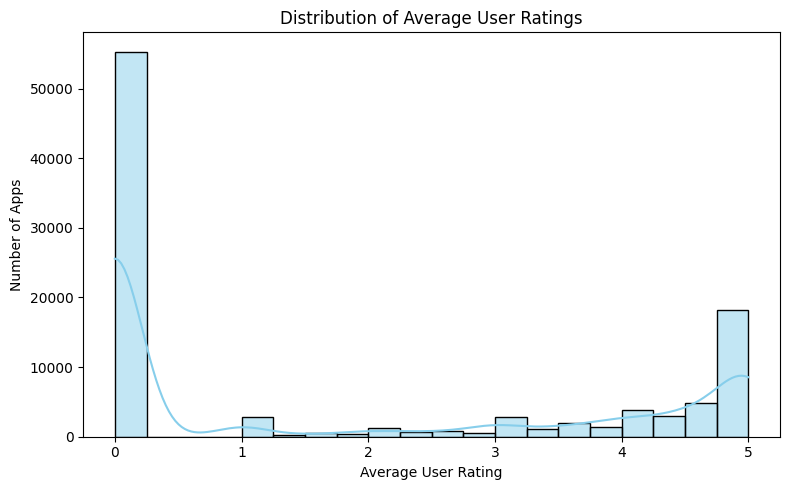

In [13]:
#Distribution of Average User Ratings
# Sample for plotting
pdf = df.sample(False, min(100000/df.count(), 1.0), seed=42).toPandas()

plt.figure(figsize=(8,5))
sns.histplot(pdf["Average_User_Rating"], bins=20, kde=True, color="skyblue")
plt.title("Distribution of Average User Ratings")
plt.xlabel("Average User Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()


/tmp/ipython-input-3414359179.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pdf, x="Is_Free", y="Average_User_Rating", palette="Set2")


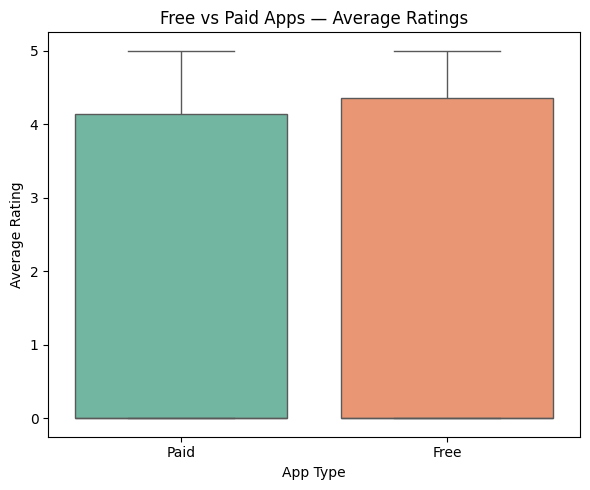

In [14]:
#Free vs Paid App Rating Comparison
plt.figure(figsize=(6,5))
sns.boxplot(data=pdf, x="Is_Free", y="Average_User_Rating", palette="Set2")
plt.xticks([0,1], ["Paid","Free"])
plt.title("Free vs Paid Apps — Average Ratings")
plt.xlabel("App Type")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()


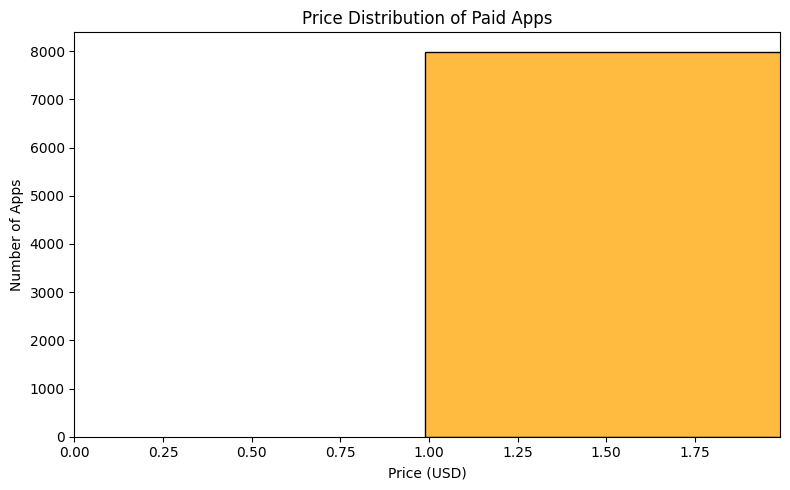

In [15]:
#Price Distribution (Paid Apps Only)
plt.figure(figsize=(8,5))
sns.histplot(pdf[pdf["Is_Free"]==0]["Price"], bins=30, color="orange")
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Apps")
plt.xlim(0, pdf["Price"].quantile(0.95)) # focus on main range
plt.tight_layout()
plt.show()


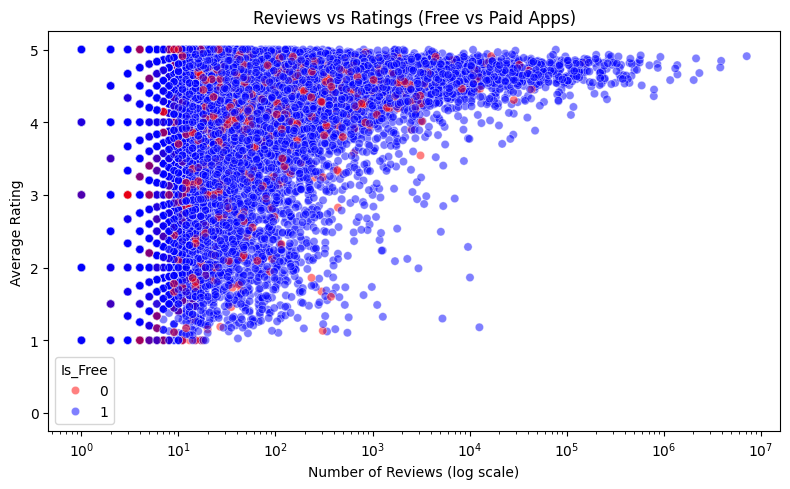

In [16]:
# Relationship Between Reviews and Ratings
plt.figure(figsize=(8,5))
sns.scatterplot(data=pdf, x="Reviews", y="Average_User_Rating", hue="Is_Free",
                palette={1:"blue", 0:"red"}, alpha=0.5)
plt.xscale("log")
plt.title("Reviews vs Ratings (Free vs Paid Apps)")
plt.xlabel("Number of Reviews (log scale)")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()


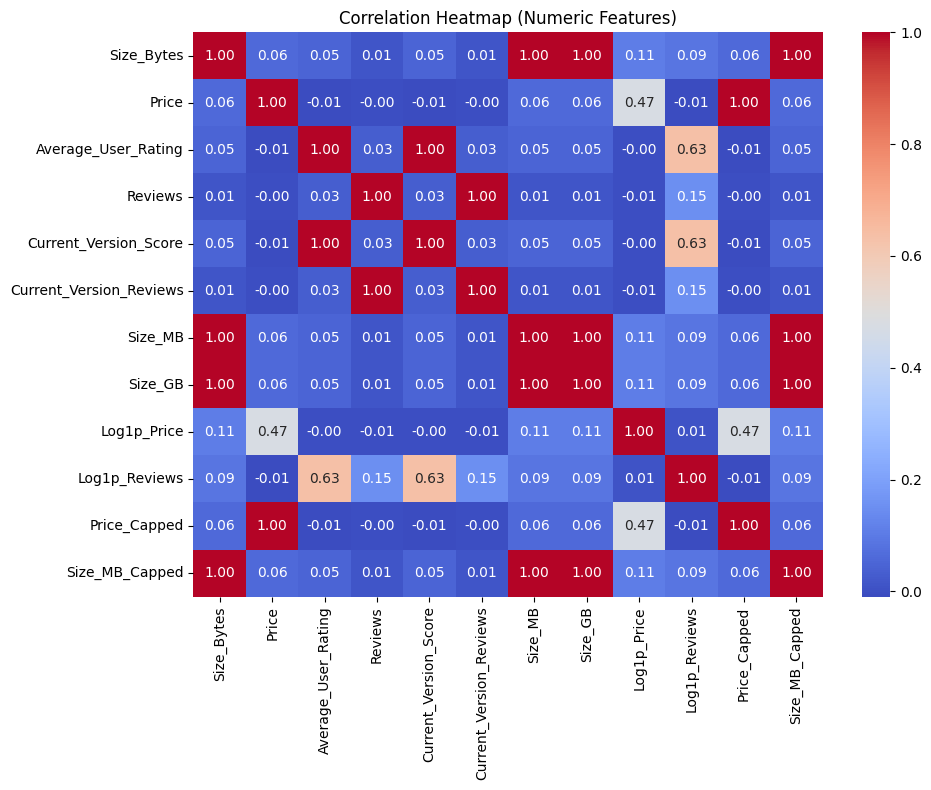

In [17]:
#correlation heatmap
# Sample from Spark for plotting (avoid memory issues)
pdf = df.sample(False, min(100000/df.count(), 1.0), seed=42).toPandas()

# Select numeric columns only
num_cols = pdf.select_dtypes(include=["float64", "int64"]).columns

# Compute correlation matrix
corr_matrix = pdf[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()


In [18]:
# 7) SAVE CURATED DATASET (PARQUET + PARTITIONS)
PARQUET_DIR = "/content/curated_parquet"
shutil.rmtree(PARQUET_DIR, ignore_errors=True)

partition_col = "Primary_Genre" if "Primary_Genre" in df.columns else None
writer = (df.write.mode("overwrite").option("compression", "snappy"))
if partition_col:
    writer = writer.partitionBy(partition_col)
writer.parquet(PARQUET_DIR)

df_cur = spark.read.parquet(PARQUET_DIR)
print("Curated rows:", df_cur.count(), "Files:", len(df_cur.inputFiles()))


Curated rows: 1230353 Files: 156


Now I have a clean, compressed, partitioned dataset stored as Parquet.

In [19]:
#8) MLlib pipelines — Regression & Classification with Cross-Validation
#8.1 Feature prep (index → one-hot → assemble → scale)
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

target = "Average_User_Rating"
use_num = [c for c in ["Price_Capped","Size_MB_Capped","App_Age_days","Days_Since_Update","Log1p_Reviews"] if c in df_cur.columns]
use_cat = [c for c in ["Primary_Genre","Content_Rating","Currency"] if c in df_cur.columns]

stages = []
for c in use_cat:
    idx = StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    oh  = OneHotEncoder(inputCols=[f"{c}_idx"], outputCols=[f"{c}_oh"])
    stages += [idx, oh]

assembler = VectorAssembler(
    inputCols=use_num + [f"{c}_oh" for c in use_cat],
    outputCol="features_raw",
    handleInvalid="keep"
)
scaler = StandardScaler(inputCol="features_raw", outputCol="features")
stages += [assembler, scaler]


This block is preparing your features for a Spark MLlib machine learning pipeline (regression/classification)

In [20]:
#Regression (predict rating)
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql.functions import lit

# Filter out rows with NaN in Log1p_Price
reg_df = df_cur.filter(F.col(target).isNotNull()).filter(F.col("Log1p_Price").isNotNull())

# Fill missing values in capped columns with median
if "Price_Capped" in reg_df.columns:
    median_price_capped = reg_df.approxQuantile("Price_Capped", [0.5], 0.01)[0]
    reg_df = reg_df.fillna({"Price_Capped": median_price_capped})

if "Size_MB_Capped" in reg_df.columns:
    median_size_mb_capped = reg_df.approxQuantile("Size_MB_Capped", [0.5], 0.01)[0]
    reg_df = reg_df.fillna({"Size_MB_Capped": median_size_mb_capped})


train, test = reg_df.randomSplit([0.8, 0.2], seed=42)

rf = RandomForestRegressor(featuresCol="features", labelCol=target, numTrees=200, seed=42)
pipeline_reg = Pipeline(stages=stages + [rf]).fit(train)

pred_reg = pipeline_reg.transform(test)
e_rmse = RegressionEvaluator(labelCol=target, predictionCol="prediction", metricName="rmse").evaluate(pred_reg)
e_mae  = RegressionEvaluator(labelCol=target, predictionCol="prediction", metricName="mae").evaluate(pred_reg)
e_r2   = RegressionEvaluator(labelCol=target, predictionCol="prediction", metricName="r2").evaluate(pred_reg)
print(f"REG -> RMSE={e_rmse:.4f}  MAE={e_mae:.4f}  R2={e_r2:.4f}")

REG -> RMSE=0.8012  MAE=0.5563  R2=0.8615


In [21]:
# --- Get readable feature names from the 'features' vector metadata ---
meta = pred_reg.schema["features"].metadata
ml_attr = meta.get("ml_attr", {})
attrs = ml_attr.get("attrs", {})

# Collect names in index order
feature_names_by_idx = {}
for attr_type in ["binary", "numeric", "nominal"]:
    for a in attrs.get(attr_type, []):
        feature_names_by_idx[a["idx"]] = a["name"]

# If metadata missing for any reason, fall back to generic names
if not feature_names_by_idx:
    # Last resort: use assembler input names (not expanded per-category)
    from pyspark.ml.feature import VectorAssembler
    assembler_stage = [s for s in pipeline_reg.stages if isinstance(s, VectorAssembler)][0]
    feature_names = assembler_stage.getInputCols()
else:
    feature_names = [name for idx, name in sorted(feature_names_by_idx.items(), key=lambda x: x[0])]

# --- Pair names with RF importances ---
import numpy as np, pandas as pd
rf_model = pipeline_reg.stages[-1]  # RandomForestRegressionModel
importances = rf_model.featureImportances.toArray()

n = min(len(feature_names), len(importances))
fi_df = pd.DataFrame({
    "feature": feature_names[:n],
    "importance": importances[:n]
}).sort_values("importance", ascending=False)

fi_df.head(20)


,feature,importance
4,Log1p_Reviews,0.940762
2,App_Age_days,0.026711
5,Primary_Genre_oh,0.012864
1,Size_MB_Capped,0.007884
3,Days_Since_Update,0.006465
6,Content_Rating_oh,0.001647
0,Price_Capped,0.000255
7,Currency_oh,0.000012


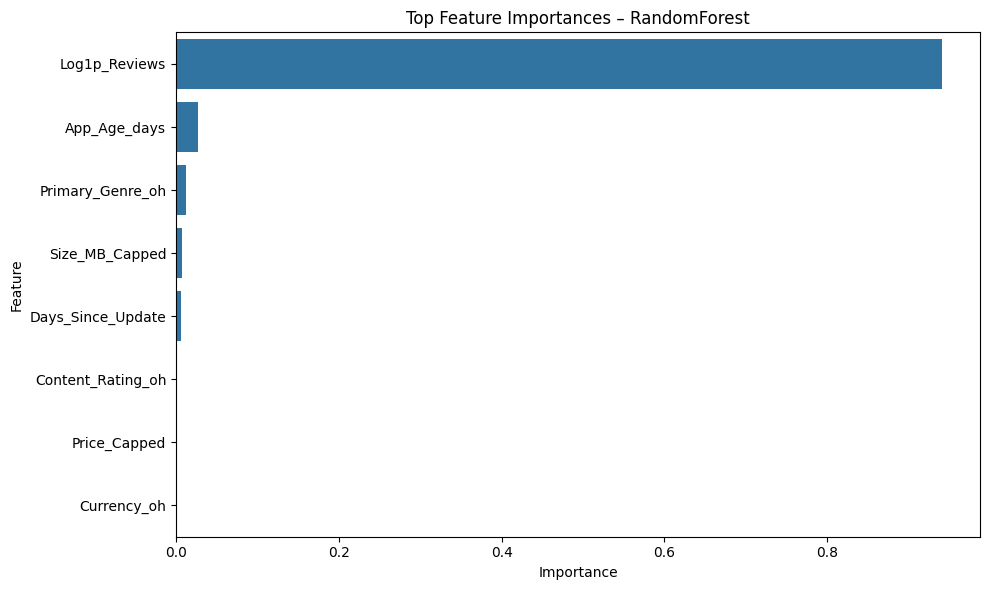

In [22]:
#plot the top features:
topk = 20
plt.figure(figsize=(10,6))
sns.barplot(data=fi_df.head(topk), x="importance", y="feature")
plt.title("Top Feature Importances – RandomForest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

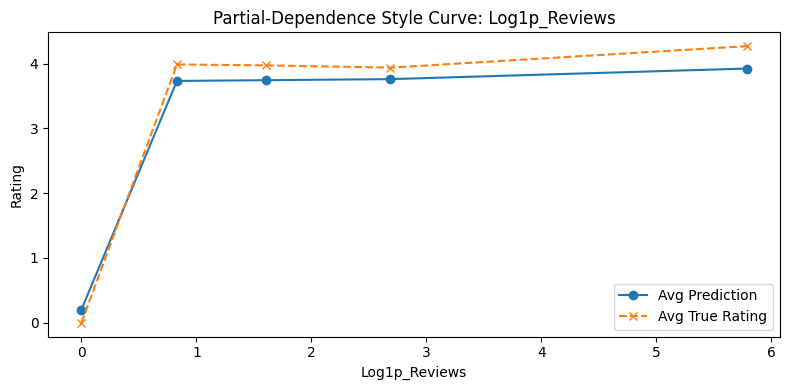

Saved: /content/plots/pdp_Log1p_Reviews.png


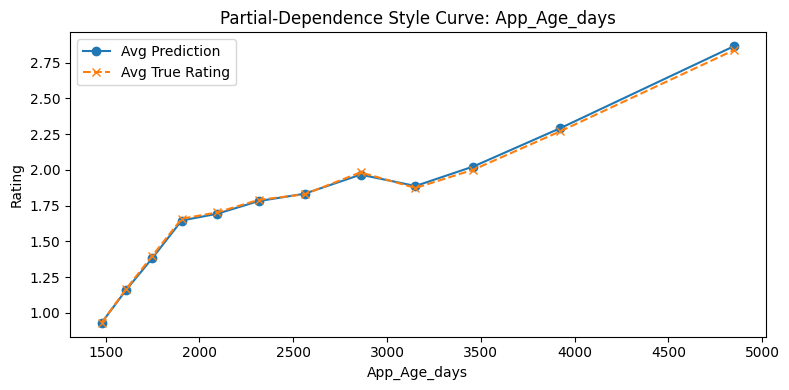

Saved: /content/plots/pdp_App_Age_days.png


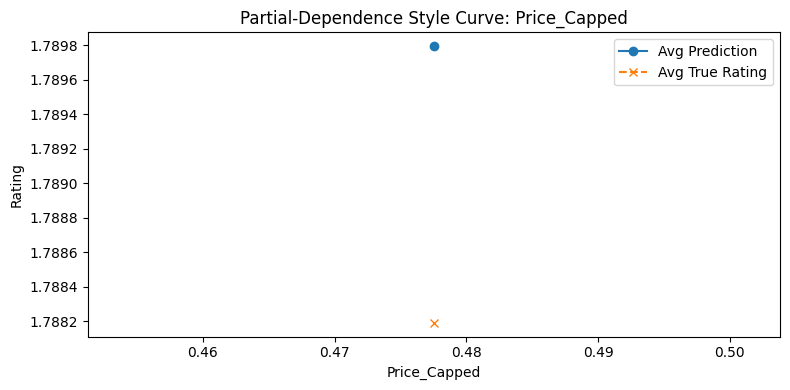

Saved: /content/plots/pdp_Price_Capped.png


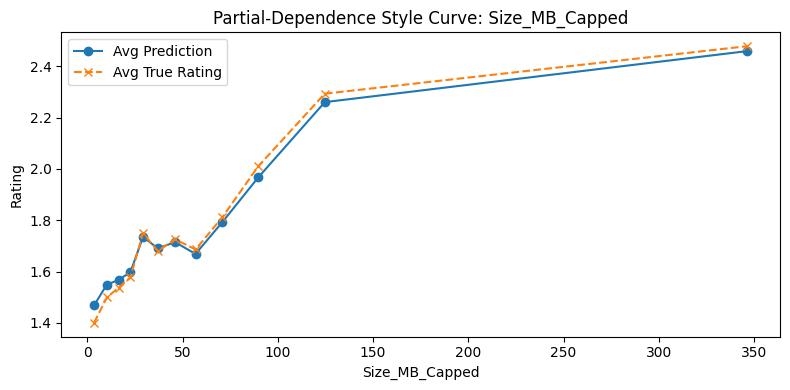

Saved: /content/plots/pdp_Size_MB_Capped.png


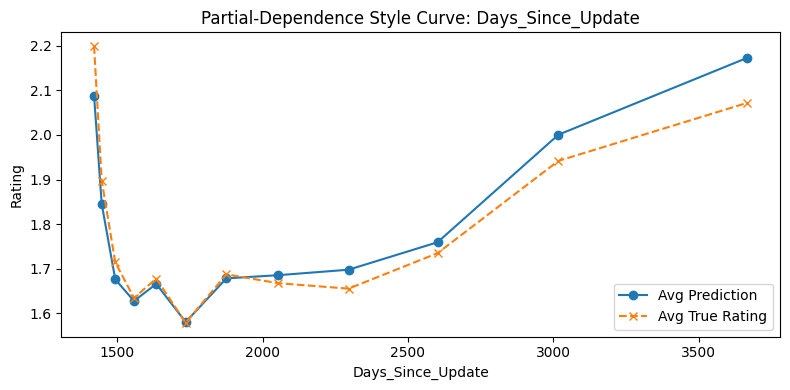

Saved: /content/plots/pdp_Days_Since_Update.png


In [23]:
#Partial-dependence–style curves (interpretability)
from pyspark.ml.feature import QuantileDiscretizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Use the test set predictions you already have (pred_reg)
work = pred_reg

def pdp_for_numeric(col, bins=12):
    # bin by quantiles (robust & scalable)
    disc = QuantileDiscretizer(numBuckets=bins, inputCol=col, outputCol=f"{col}_bin", handleInvalid="skip")
    model = disc.fit(work.select(col).where(F.col(col).isNotNull()))
    binned = model.transform(work.where(F.col(col).isNotNull()))

    # average prediction & true rating per bin
    agg = (binned.groupBy(f"{col}_bin")
                  .agg(F.avg(col).alias(col+"_avg"),
                       F.avg("prediction").alias("pred_avg"),
                       F.avg("Average_User_Rating").alias("label_avg"),
                       F.count("*").alias("n"))
                  .orderBy(f"{col}_bin"))
    pdf = agg.toPandas()
    # plot
    plt.figure(figsize=(8,4))
    plt.plot(pdf[col+"_avg"], pdf["pred_avg"], marker="o", label="Avg Prediction")
    plt.plot(pdf[col+"_avg"], pdf["label_avg"], marker="x", linestyle="--", label="Avg True Rating")
    plt.title(f"Partial-Dependence Style Curve: {col}")
    plt.xlabel(col); plt.ylabel("Rating")
    plt.legend(); plt.tight_layout()
    # Create directory if it doesn't exist
    os.makedirs("/content/plots", exist_ok=True)
    out = f"/content/plots/pdp_{col}.png"
    plt.savefig(out, dpi=150); plt.show()
    print("Saved:", out)

# run PDPs for your key numeric features that exist
for c in ["Log1p_Reviews","App_Age_days","Price_Capped","Size_MB_Capped","Days_Since_Update"]:
    if c in work.columns:
        pdp_for_numeric(c, bins=12)

In [24]:
#Train CV-tuned classifier (paste & run)
from pyspark.sql import functions as F
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml import Pipeline
from pyspark.sql.functions import lit

# Label: High rating (>= 4.5)
cls_df = df_cur.withColumn("High_Rating", F.when(F.col(target) >= 4.5, 1).otherwise(0))\
               .filter(F.col(target).isNotNull())

# Identify columns used in the VectorAssembler for classification
use_num_cls = [c for c in ["Price_Capped","Size_MB_Capped","App_Age_days","Days_Since_Update","Log1p_Reviews"] if c in cls_df.columns]
use_cat_cls = [c for c in ["Primary_Genre","Content_Rating","Currency"] if c in cls_df.columns]
pipeline_cols_cls = use_num_cls + use_cat_cls

# Fill missing numeric values with median in cls_df
for col in use_num_cls:
    if col in cls_df.columns:
        median_val = cls_df.approxQuantile(col, [0.5], 0.01)[0]
        cls_df = cls_df.fillna({col: median_val})

# Fill missing categorical values with a placeholder (e.g., "Unknown") in cls_df
for col in use_cat_cls:
     if col in cls_df.columns:
         cls_df = cls_df.fillna({col: "Unknown"})


train_c, test_c = cls_df.randomSplit([0.8, 0.2], seed=42)

lr = LogisticRegression(featuresCol="features", labelCol="High_Rating", maxIter=50)

paramGrid = (ParamGridBuilder()
             .addGrid(lr.regParam, [0.0, 0.01, 0.1])
             .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
             .build())

cv = CrossValidator(
    estimator=Pipeline(stages=stages + [lr]),
    estimatorParamMaps=paramGrid,
    evaluator=BinaryClassificationEvaluator(labelCol="High_Rating"),
    numFolds=3, parallelism=2, seed=42
)

cv_model = cv.fit(train_c)
pred_cv   = cv_model.transform(test_c)

evaluator = BinaryClassificationEvaluator(labelCol="High_Rating")
auc = evaluator.evaluate(pred_cv)
acc = (pred_cv.select((F.col("prediction")==F.col("High_Rating")).cast("int").alias("ok"))
               .agg(F.avg("ok")).first()[0])
print(f"CLS (CV best) -> Accuracy={acc:.4f}  ROC-AUC={auc:.4f}")

CLS (CV best) -> Accuracy=0.7770  ROC-AUC=0.8450


In [25]:
#Confusion matrix (TP/TN/FP/FP)
cm = (pred_cv.withColumn("pred", F.col("prediction").cast("int"))
              .groupBy("High_Rating","pred").count()
              .orderBy("High_Rating","pred"))
cm.show()

+-----------+----+------+
|High_Rating|pred| count|
+-----------+----+------+
|          0|   0|181367|
|          0|   1|  8078|
|          1|   0| 46835|
|          1|   1|  9983|
+-----------+----+------+



In [26]:
#Calculate precision, recall, F1-score
from pyspark.sql import functions as F

TP = 9983
FP = 8078
FN = 46835
TN = 181367

precision = TP / (TP + FP)
recall    = TP / (TP + FN)
f1_score  = 2 * (precision * recall) / (precision + recall)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1_score:.4f}")


Precision: 0.5527
Recall:    0.1757
F1-score:  0.2666


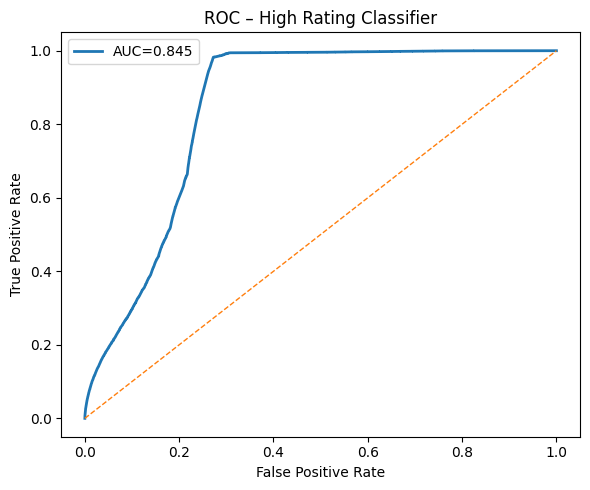

Best threshold ~ 0.20 (F1=0.600)


In [27]:
#ROC curve + best threshold
# probability of class 1
from pyspark.sql.types import ArrayType, DoubleType
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col, when, size, lit

pred_cv2 = pred_cv.withColumn("prob_array", vector_to_array(col("probability")))\
                  .withColumn("p1", when(size(col("prob_array")) > 1, col("prob_array")[1]).otherwise(lit(0.5)))\
                  .select("High_Rating","p1")

# sample for plotting
pdf = pred_cv2.sample(False, min(150_000/pred_cv2.count(), 1.0), seed=42).toPandas()

from sklearn.metrics import roc_curve, auc, f1_score, precision_score, recall_score
import numpy as np, matplotlib.pyplot as plt

fpr, tpr, thr = roc_curve(pdf["High_Rating"], pdf["p1"])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, lw=2, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],"--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC – High Rating Classifier"); plt.legend(); plt.tight_layout()
plt.savefig("/content/plots/roc_curve_cls.png", dpi=150); plt.show()

# threshold search to maximise F1
grid = np.linspace(0.1,0.9,17); y = pdf["High_Rating"].values; p = pdf["p1"].values
best = max(((f1_score(y,(p>=t).astype(int)), t) for t in grid), key=lambda z: z[0])
best_t = best[1]
print(f"Best threshold ~ {best_t:.2f} (F1={best[0]:.3f})")

In [28]:
# --- Build readable feature names even if 'features' metadata is missing ---

from pyspark.ml.feature import OneHotEncoderModel, VectorAssembler
import pandas as pd
import numpy as np

# 1) Grab the best fitted pipeline from CV
best_pipeline = cv_model.bestModel
stages_best = best_pipeline.stages

# 2) Find the OneHotEncoderModel and the VectorAssembler used in the pipeline
ohe_model = next(s for s in stages_best if isinstance(s, OneHotEncoderModel))
assembler = next(s for s in stages_best if isinstance(s, VectorAssembler))

# 3) For each assembler input column:
#    - if it's an OHE vector (ends with "_oh"), expand into category-sized names
#    - otherwise keep the numeric feature name
input_cols = list(assembler.getInputCols())            # order used to build the vector
ohe_out_cols = list(ohe_model.getOutputCols())         # e.g. ["Primary_Genre_oh", ...]
ohe_sizes    = list(ohe_model.categorySizes)           # vector length per OHE output

feature_names = []
for col in input_cols:
    if col in ohe_out_cols:
        j = ohe_out_cols.index(col)
        k = ohe_sizes[j]
        base = col.replace("_oh", "")
        feature_names.extend([f"{base}__cat_{i}" for i in range(k)])
    else:
        feature_names.append(col)

# 4) Now align names with LR coefficients
best_lr = stages_best[-1]   # LogisticRegressionModel
coefs_arr = best_lr.coefficients.toArray()

# If the vector was longer than the names (rare), trim; if shorter, pad (shouldn't happen)
n = min(len(feature_names), len(coefs_arr))
coefs = pd.Series(coefs_arr[:n], index=feature_names[:n]).sort_values(ascending=False)

print("Top positive drivers:")
display(coefs.head(15))
print("\nTop negative drivers:")
display(coefs.tail(15))


Top positive drivers:


,0
Log1p_Reviews,0.787465
Primary_Genre__cat_4,0.014400
Size_MB_Capped,0.000000
Price_Capped,0.000000
Primary_Genre__cat_0,0.000000
App_Age_days,0.000000
Primary_Genre__cat_2,0.000000
Primary_Genre__cat_1,0.000000
Primary_Genre__cat_6,0.000000
Primary_Genre__cat_5,0.000000



Top negative drivers:


,0
Primary_Genre__cat_22,0.000000
Primary_Genre__cat_15,0.000000
Primary_Genre__cat_16,0.000000
Primary_Genre__cat_17,0.000000
Primary_Genre__cat_18,0.000000
Primary_Genre__cat_19,0.000000
Primary_Genre__cat_20,0.000000
Primary_Genre__cat_25,0.000000
Primary_Genre__cat_26,0.000000
Primary_Genre__cat_23,0.000000


In [29]:
#Summarize classifier metrics (incl. best threshold)
# --- metrics at default 0.5 ---
from pyspark.sql import functions as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col, when, size, lit

pdf_05 = pred_cv.withColumn("prob_array", vector_to_array(col("probability")))\
                .withColumn("p1", when(size(col("prob_array")) > 1, col("prob_array")[1]).otherwise(lit(0.5)))\
                .select("High_Rating","p1") \
                .toPandas()
y_true = pdf_05["High_Rating"].values
y_pred05 = (pdf_05["p1"].values >= 0.5).astype(int)

pr05, rc05, f105, _ = precision_recall_fscore_support(y_true, y_pred05, average="binary", zero_division=0)
acc05 = accuracy_score(y_true, y_pred05)

# --- metrics at best threshold (from your ROC cell: best_t) ---
# Ensure best_t is defined. If the ROC cell hasn't been run, you might need a default
if 'best_t' not in locals():
    print("Warning: 'best_t' not found. Using default threshold of 0.5 for best threshold metrics.")
    best_t = 0.5 # Fallback if ROC cell wasn't run

y_predBest = (pdf_05["p1"].values >= best_t).astype(int)
prB, rcB, f1B, _ = precision_recall_fscore_support(y_true, y_predBest, average="binary", zero_division=0)
accB = accuracy_score(y_true, y_predBest)

print(f"Default 0.5 -> Acc={acc05:.3f}  Prec={pr05:.3f}  Recall={rc05:.3f}  F1={f105:.3f}")
print(f"Best  {best_t:.2f} -> Acc={accB:.3f}  Prec={prB:.3f}  Recall={rcB:.3f}  F1={f1B:.3f}")

Default 0.5 -> Acc=0.777  Prec=0.553  Recall=0.176  F1=0.267
Best  0.20 -> Acc=0.768  Prec=0.498  Recall=0.756  F1=0.601


In [30]:
#Produce a tidy “Results table” for appendix
results_summary = pd.DataFrame({
    "Metric": ["RMSE (regression)", "MAE (regression)", "R2 (regression)",
               "Accuracy@0.5", "Precision@0.5", "Recall@0.5", "F1@0.5",
               f"Accuracy@{best_t:.2f}", f"Precision@{best_t:.2f}", f"Recall@{best_t:.2f}", f"F1@{best_t:.2f}"],
    "Value": [e_rmse, e_mae, e_r2, acc05, pr05, rc05, f105, accB, prB, rcB, f1B]
})
results_summary


,Metric,Value
0,RMSE (regression),0.801232
1,MAE (regression),0.556285
2,R2 (regression),0.861533
3,Accuracy@0.5,0.777015
4,Precision@0.5,0.552738
5,Recall@0.5,0.175701
6,F1@0.5,0.266644
7,Accuracy@0.20,0.768093
8,Precision@0.20,0.498306
9,Recall@0.20,0.755993
